In [1]:
# ==============================================================================
# Purpose:
#   Summarize DEG counts (edgeR outputs) as stacked barplots by celltype_level3.
#   - Fig F3: within-race stage contrasts (6 groups) for UP and DOWN DEGs
#   - Fig F4: NHB vs NHW within stage (3 groups) for UP and DOWN DEGs
# ==============================================================================

# Header

In [1]:
from utils import *

In [2]:
sc.settings.set_figure_params(dpi=600, dpi_save=600)  # 600 dpi for publication
sc.settings.figdir = "plots/Figure1"

rcParams.update({
    'font.family': 'Arial',
    'svg.fonttype': 'none',    # Keep SVG text as font
    'font.size': 6,            # Main font size (5–7pt recommended)
    'axes.titlesize': 7,
    'axes.labelsize': 6,
    'xtick.labelsize': 5,
    'ytick.labelsize': 5,
    'legend.fontsize': 6,
    'legend.title_fontsize': 6,
    'figure.dpi': 600,

    # --- Nature Immunology-style axes/ticks ---
    'axes.linewidth': 0.5,          # Axis lines: 0.5 pt
    'xtick.major.width': 0.5,        # Major tick lines
    'ytick.major.width': 0.5,
    'xtick.minor.width': 0.5,
    'ytick.minor.width': 0.5,
    'lines.linewidth': 0.7,          # Plot/data lines
    'axes.grid': False,              # No grid lines

    # --- Ticks on all sides ---
    'xtick.direction': 'out',
    'ytick.direction': 'out',
    'xtick.top': False,
    'xtick.bottom': False,
    'ytick.left': True,
    'ytick.right': False,


    # --- Tick label padding (minimal) ---
    'xtick.major.pad': 0,
    'ytick.major.pad': 0,

    # ---- Thin lines for Nature Immunology style ----
    'lines.linewidth': 0.5,     # General line width (default: 1.5)
    'patch.linewidth': 0.5,     # Outline for violin/bars (default: 1.0)
    
})

# plt.rcParams['axes.grid'] = False      # Extra guarantee, if using seaborn
# sns.set_style("white")                 # Removes upper/right axes and grid

# -- Scanpy vector-friendly mode --
sc.settings._vector_friendly = True

In [3]:
cells_ordered = [
    'Naive B','Mature B','Memory B','Plasmablast',
    'Naive CD4T','Central Memory CD4T','Effector Memory CD4T','Cytotoxic CD4T','Treg',
    'Naive CD8T','Central Memory CD8T','Effector Memory CD8T',
    'Double Negative T','γδ T','MAIT',
    'cDC1','cDC2','pDC',
    'Classical Monocyte','Intermediate Monocyte','Nonclassical Monocyte','Cytotoxic Monocyte',
    'CD56-dim NK','CD56-bright NK','Proliferating NK'
]

In [4]:
cells_group = {
    'B':['Naive B',
 'Mature B',
 'Memory B',
 'Plasmablast'],
    'T':['Naive CD4T',
 'Central Memory CD4T',
 'Effector Memory CD4T',
 'Cytotoxic CD4T',
 'Treg',
 'Naive CD8T',
 'Central Memory CD8T',
 'Effector Memory CD8T',
 'Double Negative T',
 'γδ T',
 'MAIT'],
    'DC':[
   'cDC1',
 'cDC2',
 'pDC'     
    ],
    'Mono':[
        'Classical Monocyte',
 'Intermediate Monocyte',
 'Nonclassical Monocyte',
 'Cytotoxic Monocyte'
        ],
    'NK':[
        'CD56-dim NK',
 'CD56-bright NK',
 'Proliferating NK'
    ]
}


In [5]:
os.chdir('../')

# By race

In [6]:
deg = pd.read_csv(
    'data/07RRE_pb_deg_fgsea/DEG_NHBvsNHW_celltypelevel3_EachDiseaseStage.csv', # DEG_NHBvsNHW_celltypelevel3_EachDiseaseStage.csv
    index_col = 0
              )

deg

,gene,logFC,logCPM,LR,PValue,FDR,group,celltype
1,SNHG5,-1.239241,7.089362,3.079671e+01,2.865230e-08,0.000282,HRL,Naive B
2,MT-ND3,-0.889038,10.687938,2.708684e+01,1.945174e-07,0.000957,HRL,Naive B
3,LINC01505,2.152315,4.123511,2.350496e+01,1.245925e-06,0.003429,HRL,Naive B
4,MTRNR2L8,-6.978741,10.017144,2.328946e+01,1.393613e-06,0.003429,HRL,Naive B
5,PSPH,1.918980,3.095556,2.179748e+01,3.029982e-06,0.005964,HRL,Naive B
...,...,...,...,...,...,...,...,...
488345,RBBP4,-0.001241,8.817069,6.542229e-06,9.979592e-01,0.999619,BC,Proliferating NK
488346,DHRS7,0.000336,8.846212,2.022053e-06,9.988654e-01,0.999619,BC,Proliferating NK
488347,RPL35A,-0.000164,11.170459,1.456396e-06,9.990371e-01,0.999619,BC,Proliferating NK
488348,SSR2,-0.000832,9.144718,1.303903e-06,9.990889e-01,0.999619,BC,Proliferating NK


## Counter

In [7]:
deg_ft = deg[deg['FDR']<0.1] # deg[(deg['FDR']<0.1) & (deg['logFC']>0)]

for group in ['HRL','DCIS','BC']:
    sub = deg_ft[deg_ft['group']==group]
    num = sub['gene'].unique().shape
    print(group, num)

# Counter(deg_ft['subgroup'])

HRL (212,)
DCIS (57,)
BC (1659,)


In [8]:
deg_ft = deg[deg['FDR']<0.1] # deg[(deg['FDR']<0.1) & (deg['logFC']>0)]
tmpdict = {}

for cell in deg_ft['celltype'].unique():
    sub = deg_ft[deg_ft['celltype']==cell]
    num = sub['gene'].unique().shape
    tmpdict[cell] = num

tmpout = pd.Series(tmpdict).sort_values(ascending=False)
tmpout

Naive B                  (418,)
Classical Monocyte       (389,)
Mature B                 (326,)
Central Memory CD4T      (252,)
Naive CD4T               (251,)
Intermediate Monocyte    (212,)
Effector Memory CD4T     (177,)
Nonclassical Monocyte    (158,)
CD56-dim NK              (126,)
cDC2                     (108,)
Naive CD8T                (42,)
MAIT                      (41,)
pDC                       (40,)
Cytotoxic Monocyte        (28,)
Memory B                  (25,)
Effector Memory CD8T      (25,)
Treg                      (14,)
CD56-bright NK             (9,)
Central Memory CD8T        (9,)
Cytotoxic CD4T             (7,)
Plasmablast                (7,)
γδ T                       (2,)
Double Negative T          (1,)
cDC1                       (1,)
Proliferating NK           (1,)
dtype: object

In [9]:
deg_ft.head(3)

,gene,logFC,logCPM,LR,PValue,FDR,group,celltype
1,SNHG5,-1.239241,7.089362,30.796712,2.865230e-08,0.000282,HRL,Naive B
2,MT-ND3,-0.889038,10.687938,27.086843,1.945174e-07,0.000957,HRL,Naive B
3,LINC01505,2.152315,4.123511,23.504955,1.245925e-06,0.003429,HRL,Naive B


In [10]:
for group in ['HRL','DCIS','BC']:

    tmp = deg_ft[deg_ft['group']==group]

    bar = pd.crosstab(tmp['celltype'], tmp['gene']).sum(axis=1).sort_values(ascending=False)
    print(group, bar.iloc[:5,],'\n\n')


HRL celltype
Classical Monocyte       93
Nonclassical Monocyte    48
Intermediate Monocyte    44
Naive CD4T               25
Central Memory CD4T      18
dtype: int64 


DCIS celltype
Mature B                25
pDC                     10
Memory B                 6
Effector Memory CD4T     4
Plasmablast              3
dtype: int64 


BC celltype
Naive B                405
Classical Monocyte     310
Mature B               307
Central Memory CD4T    241
Naive CD4T             230
dtype: int64 




## Export

In [11]:
dft = deg[['celltype','group','gene','logFC','PValue','FDR']]
dft.columns = ['cell type','comparison group','gene','log2 fold change','p-value','FDR']

dft

,cell type,comparison group,gene,log2 fold change,p-value,FDR
1,Naive B,HRL,SNHG5,-1.239241,2.865230e-08,0.000282
2,Naive B,HRL,MT-ND3,-0.889038,1.945174e-07,0.000957
3,Naive B,HRL,LINC01505,2.152315,1.245925e-06,0.003429
4,Naive B,HRL,MTRNR2L8,-6.978741,1.393613e-06,0.003429
5,Naive B,HRL,PSPH,1.918980,3.029982e-06,0.005964
...,...,...,...,...,...,...
488345,Proliferating NK,BC,RBBP4,-0.001241,9.979592e-01,0.999619
488346,Proliferating NK,BC,DHRS7,0.000336,9.988654e-01,0.999619
488347,Proliferating NK,BC,RPL35A,-0.000164,9.990371e-01,0.999619
488348,Proliferating NK,BC,SSR2,-0.000832,9.990889e-01,0.999619


In [12]:
dft.to_csv('data/Tables/RRE_ST_DEbyRace.csv')

## Total

In [13]:
deg_ft = deg[(deg['FDR']<0.1)]#deg[(deg['PValue']<0.05) & (deg['logFC']>0)]


tbl = pd.crosstab(deg_ft['celltype'], deg_ft['group'])
tbl

group,BC,DCIS,HRL
celltype,,,
CD56-bright NK,5,0,4
CD56-dim NK,121,0,8
Central Memory CD4T,241,0,18
Central Memory CD8T,5,0,4
Classical Monocyte,310,2,93
Cytotoxic CD4T,1,1,5
Cytotoxic Monocyte,15,0,13
Double Negative T,0,0,1
Effector Memory CD4T,166,4,9


In [14]:
# 1. Wide to long
tbl_long = tbl.reset_index().melt(id_vars='celltype', var_name='group', value_name='count')

# 2. Assign main cell type group
cells_group = {
    'B': ['Naive B', 'Mature B', 'Memory B', 'Plasmablast'],
    'T': ['Naive CD4T', 'Central Memory CD4T', 'Effector Memory CD4T', 'Cytotoxic CD4T', 'Treg', 'Naive CD8T', 'Central Memory CD8T', 'Effector Memory CD8T', 'Double Negative T', 'γδ T', 'MAIT'],
    'DC': ['cDC1', 'cDC2', 'pDC'],
    'Mono': ['Classical Monocyte', 'Intermediate Monocyte', 'Nonclassical Monocyte', 'Cytotoxic Monocyte'],
    'NK': ['CD56-dim NK', 'CD56-bright NK', 'Proliferating NK']
}
cell2group = {c: k for k, v in cells_group.items() for c in v}
tbl_long['main_group'] = tbl_long['celltype'].map(cell2group)

# 3. Order x by sum per celltype (across all disease groups)
celltype_sum = tbl_long.groupby('celltype')['count'].sum().sort_values(ascending=False)
celltype_order = celltype_sum.index.tolist()
# celltype_order = tbl_long[tbl_long['group'].isin(['BC'])].sort_values(by='count',ascending=False)['celltype'].tolist()

# 4. Define color mapping for main groups
# major_celltype_palette = {
#     'B':    '#3072C4',
#     'T':    '#EF763F',
#     'DC':   '#35A293',
#     'Mono': '#B3813E',
#     'NK':   '#7D4C99'
# }

group_palette = {
    'HRL':'skyblue',
    'DCIS':'#825CA6',
    'BC':'#06948E'
}

tbl_long

,celltype,group,count,main_group
0,CD56-bright NK,BC,5,NK
1,CD56-dim NK,BC,121,NK
2,Central Memory CD4T,BC,241,T
3,Central Memory CD8T,BC,5,T
4,Classical Monocyte,BC,310,Mono
...,...,...,...,...
70,Treg,HRL,7,T
71,cDC1,HRL,0,DC
72,cDC2,HRL,7,DC
73,pDC,HRL,4,DC


/tmp/ipykernel_3147241/3445453716.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


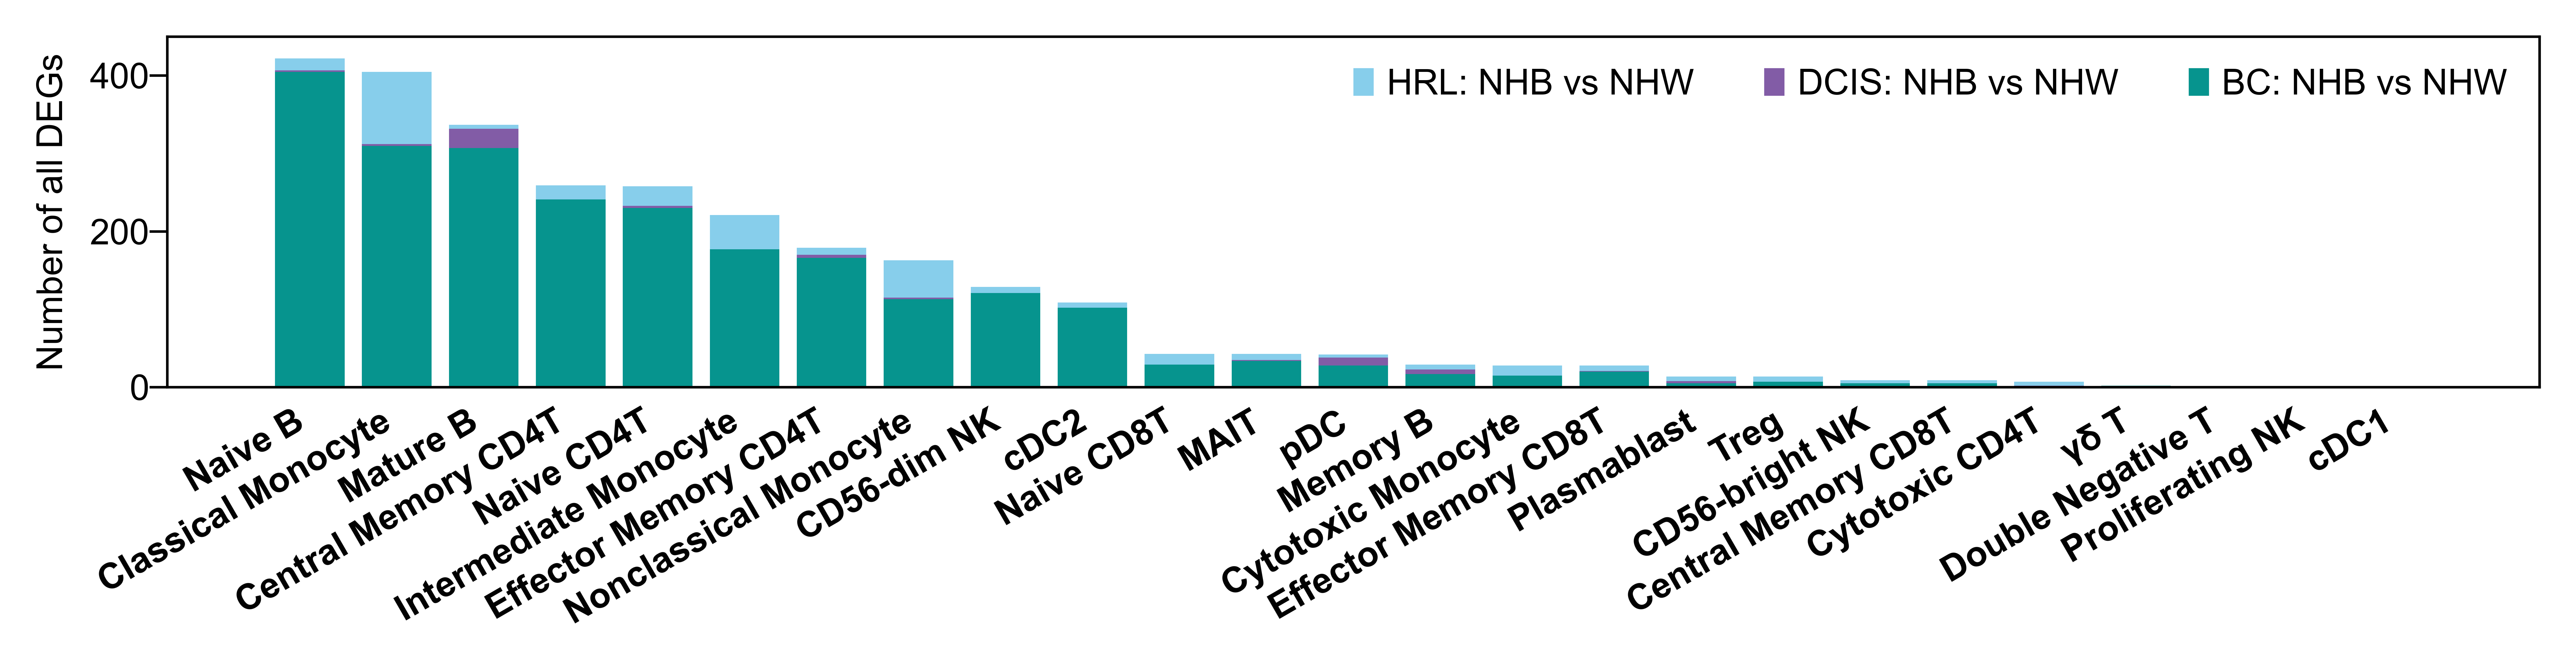

In [16]:
import matplotlib.pyplot as plt
import pandas as pd

# define order explicitly
hue_order = [
    'HRL',
    'DCIS',
    'BC'
]

# pivot to wide format
tbl_wide = (
    tbl_long
    .pivot_table(
        index='celltype',
        columns='group',
        values='count',
        aggfunc='sum'
    )
    .reindex(index=celltype_order, columns=hue_order)
    .fillna(0)
)

# plotting
fig, ax = plt.subplots(figsize=(7, 1.8))

bottom = pd.Series(0, index=tbl_wide.index)

for grp in reversed(hue_order):
    ax.bar(
        tbl_wide.index,
        tbl_wide[grp],
        bottom=bottom,
        color=group_palette[grp],
        label=grp
    )
    bottom += tbl_wide[grp]

# 🔑 FIX: set y-limits using stacked total
ax.set_ylim(0, 450)#bottom.max() * 1.05)

# formatting
ax.set_xlabel('')
ax.set_ylabel('Number of all DEGs', fontsize=7)
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=30,
    ha='right',
    fontsize=7,
    fontweight='bold'
)
ax.tick_params(axis='y', labelsize=7)


# legend (top-to-bottom order preserved)
handles = [
    plt.Rectangle((0, 0), 1, 1, color=group_palette[g])
    for g in hue_order
]
ax.legend(
    handles,
    ['HRL: NHB vs NHW', 'DCIS: NHB vs NHW', 'BC: NHB vs NHW'], # hue_order is ['HRL', 'DCIS', 'BC']
    title='',
    bbox_to_anchor=(1, 1),
    loc='upper right',
    frameon=False,
    fontsize=7,
    ncol=3
)

plt.tight_layout()
plt.savefig('plots/F4/RRE_numDEG_bysrace_total.svg')

# By Disease State

In [17]:
deg = pd.read_csv(
    'data/07RRE_pb_deg_fgsea/DEG_BCvsDCISvsHRL_celltypelevel3_EachRaceGroup.csv', 
    index_col = 0
              )

deg

,gene,logFC,logCPM,LR,PValue,FDR,subgroup,celltype
1,MTRNR2L8,-6.676910,10.017144,15.464890,0.000084,0.435324,DCIS_vs_HRL_NHW,Naive B
2,GALNT2,-0.742416,5.880818,14.698274,0.000126,0.435324,DCIS_vs_HRL_NHW,Naive B
3,MTHFD2L,-0.680165,4.795262,14.602943,0.000133,0.435324,DCIS_vs_HRL_NHW,Naive B
4,TMEM69,0.793512,4.231095,13.872469,0.000196,0.481332,DCIS_vs_HRL_NHW,Naive B
5,HIF1A,-0.590263,7.244593,12.214944,0.000474,0.590851,DCIS_vs_HRL_NHW,Naive B
...,...,...,...,...,...,...,...,...
976694,CALM1,0.000699,11.452634,0.000040,0.994979,0.998031,BC_vs_HRL_NHB,Proliferating NK
976695,GPS2,0.001227,8.268491,0.000033,0.995441,0.998031,BC_vs_HRL_NHB,Proliferating NK
976696,CALM3,-0.000804,9.464676,0.000016,0.996780,0.998453,BC_vs_HRL_NHB,Proliferating NK
976697,NDUFB4,-0.001062,8.510251,0.000009,0.997590,0.998453,BC_vs_HRL_NHB,Proliferating NK


## Counter

In [18]:
deg_ft = deg[deg['FDR']<0.1] # deg[(deg['FDR']<0.1) & (deg['logFC']>0)]

for group in ['BC_vs_HRL_NHB', 'BC_vs_DCIS_NHB', 'DCIS_vs_HRL_NHB', 
              'BC_vs_HRL_NHW', 'BC_vs_DCIS_NHW', 'DCIS_vs_HRL_NHW']:
    sub = deg_ft[deg_ft['subgroup']==group]
    num = sub['gene'].unique().shape
    print(group, num)

# Counter(deg_ft['subgroup'])

BC_vs_HRL_NHB (4897,)
BC_vs_DCIS_NHB (214,)
DCIS_vs_HRL_NHB (43,)
BC_vs_HRL_NHW (1094,)
BC_vs_DCIS_NHW (9,)
DCIS_vs_HRL_NHW (10,)


In [19]:
deg_ft = deg[deg['FDR']<0.1] # deg[(deg['FDR']<0.1) & (deg['logFC']>0)]
tmpdict = {}

for cell in deg_ft['celltype'].unique():
    sub = deg_ft[deg_ft['celltype']==cell]
    num = sub['gene'].unique().shape
    tmpdict[cell] = num

tmpout = pd.Series(tmpdict).sort_values(ascending=False)
tmpout

Classical Monocyte       (2143,)
Central Memory CD4T      (1684,)
Nonclassical Monocyte    (1533,)
Naive CD4T                (960,)
MAIT                      (592,)
Cytotoxic Monocyte        (574,)
Intermediate Monocyte     (537,)
cDC2                      (492,)
Effector Memory CD8T      (429,)
Mature B                  (403,)
CD56-dim NK               (364,)
Memory B                  (312,)
pDC                       (312,)
Effector Memory CD4T      (290,)
Treg                      (283,)
Naive B                   (242,)
Naive CD8T                (155,)
Central Memory CD8T        (92,)
Plasmablast                (47,)
CD56-bright NK             (42,)
Cytotoxic CD4T             (32,)
Proliferating NK           (28,)
cDC1                        (5,)
γδ T                        (1,)
dtype: object

In [20]:
Counter(deg_ft['subgroup'])

Counter({'BC_vs_HRL_NHB': 10081,
         'BC_vs_HRL_NHW': 1304,
         'BC_vs_DCIS_NHB': 223,
         'DCIS_vs_HRL_NHB': 53,
         'DCIS_vs_HRL_NHW': 11,
         'BC_vs_DCIS_NHW': 9})

In [21]:
deg_ft.head(3)

,gene,logFC,logCPM,LR,PValue,FDR,subgroup,celltype
29524,IGHV1-69-2,1.332704,4.680118,24.420082,7.745704e-07,0.007623,DCIS_vs_HRL_NHB,Naive B
29525,LINC00910,1.698425,5.358746,19.374633,1.074246e-05,0.052858,DCIS_vs_HRL_NHB,Naive B
29526,GATC,-1.068165,3.845055,16.976578,3.784381e-05,0.078025,DCIS_vs_HRL_NHB,Naive B


In [22]:
for group in ['DCIS_vs_HRL_NHW',
                  'BC_vs_HRL_NHW',
                  'BC_vs_DCIS_NHW',  
                  
                  'DCIS_vs_HRL_NHB',
                  'BC_vs_HRL_NHB',
                  'BC_vs_DCIS_NHB']:

    tmp = deg_ft[deg_ft['subgroup']==group]

    bar = pd.crosstab(tmp['celltype'], tmp['gene']).sum(axis=1).sort_values(ascending=False)
    print(group, bar.iloc[:5,],'\n\n')


DCIS_vs_HRL_NHW celltype
Treg                     3
Plasmablast              3
Cytotoxic CD4T           1
Intermediate Monocyte    1
Effector Memory CD8T     1
dtype: int64 


BC_vs_HRL_NHW celltype
MAIT                    588
Effector Memory CD8T    235
Effector Memory CD4T    144
Naive CD8T              133
Naive CD4T               80
dtype: int64 


BC_vs_DCIS_NHW celltype
Plasmablast             4
Effector Memory CD4T    2
CD56-dim NK             1
Effector Memory CD8T    1
Memory B                1
dtype: int64 


DCIS_vs_HRL_NHB celltype
Central Memory CD4T      9
Effector Memory CD4T     7
Nonclassical Monocyte    6
Naive CD4T               6
Memory B                 5
dtype: int64 


BC_vs_HRL_NHB celltype
Classical Monocyte       2143
Central Memory CD4T      1671
Nonclassical Monocyte    1527
Naive CD4T                882
Cytotoxic Monocyte        572
dtype: int64 


BC_vs_DCIS_NHB celltype
pDC                      156
Memory B                  15
Central Memory CD4T       11

## Export - Supp Table

In [23]:
dft = deg[['celltype','subgroup','gene','logFC','PValue','FDR']]
dft.columns = ['cell type','comparison group','gene','log2 fold change','p-value','FDR']

dft

,cell type,comparison group,gene,log2 fold change,p-value,FDR
1,Naive B,DCIS_vs_HRL_NHW,MTRNR2L8,-6.676910,0.000084,0.435324
2,Naive B,DCIS_vs_HRL_NHW,GALNT2,-0.742416,0.000126,0.435324
3,Naive B,DCIS_vs_HRL_NHW,MTHFD2L,-0.680165,0.000133,0.435324
4,Naive B,DCIS_vs_HRL_NHW,TMEM69,0.793512,0.000196,0.481332
5,Naive B,DCIS_vs_HRL_NHW,HIF1A,-0.590263,0.000474,0.590851
...,...,...,...,...,...,...
976694,Proliferating NK,BC_vs_HRL_NHB,CALM1,0.000699,0.994979,0.998031
976695,Proliferating NK,BC_vs_HRL_NHB,GPS2,0.001227,0.995441,0.998031
976696,Proliferating NK,BC_vs_HRL_NHB,CALM3,-0.000804,0.996780,0.998453
976697,Proliferating NK,BC_vs_HRL_NHB,NDUFB4,-0.001062,0.997590,0.998453


In [24]:
dft.to_csv('data/Tables/RRE_ST_DEbyDzstate.csv')

## Total

In [25]:
deg_ft = deg[(deg['FDR']<0.1)] # deg[(deg['FDR']<0.1) & (deg['logFC']>0)]


tbl = pd.crosstab(deg_ft['celltype'], deg_ft['subgroup'])
tbl

subgroup,BC_vs_DCIS_NHB,BC_vs_DCIS_NHW,BC_vs_HRL_NHB,BC_vs_HRL_NHW,DCIS_vs_HRL_NHB,DCIS_vs_HRL_NHW
celltype,,,,,,
CD56-bright NK,0,0,18,24,0,0
CD56-dim NK,0,1,361,2,0,0
Central Memory CD4T,11,0,1671,7,9,0
Central Memory CD8T,2,0,64,28,0,0
Classical Monocyte,0,0,2143,0,0,0
Cytotoxic CD4T,1,0,30,0,1,1
Cytotoxic Monocyte,4,0,572,0,1,0
Effector Memory CD4T,4,2,141,144,7,0
Effector Memory CD8T,5,1,206,235,1,1


In [26]:
tbl.mean(axis=0)

subgroup
BC_vs_DCIS_NHB       9.291667
BC_vs_DCIS_NHW       0.375000
BC_vs_HRL_NHB      420.041667
BC_vs_HRL_NHW       54.333333
DCIS_vs_HRL_NHB      2.208333
DCIS_vs_HRL_NHW      0.458333
dtype: float64

In [27]:
# 1. Wide to long
tbl_sel = tbl[['DCIS_vs_HRL_NHW','BC_vs_HRL_NHW','BC_vs_DCIS_NHW',     
               'DCIS_vs_HRL_NHB','BC_vs_HRL_NHB','BC_vs_DCIS_NHB']]
tbl_sel.columns = ['NHW-DCIS vs HRL', 'NHW-BC vs HRL',  'NHW-BC vs DCIS',
                   'NHB-DCIS vs HRL', 'NHB-BC vs HRL',  'NHB-BC vs DCIS']

tbl_long = tbl_sel.reset_index().melt(id_vars='celltype', var_name='group', value_name='count')


# 2. Assign main cell type group
cells_group = {
    'B': ['Naive B', 'Mature B', 'Memory B', 'Plasmablast'],
    'T': ['Naive CD4T', 'Central Memory CD4T', 'Effector Memory CD4T', 'Cytotoxic CD4T', 'Treg', 'Naive CD8T', 'Central Memory CD8T', 'Effector Memory CD8T', 'Double Negative T', 'γδ T', 'MAIT'],
    'DC': ['cDC1', 'cDC2', 'pDC'],
    'Mono': ['Classical Monocyte', 'Intermediate Monocyte', 'Nonclassical Monocyte', 'Cytotoxic Monocyte'],
    'NK': ['CD56-dim NK', 'CD56-bright NK', 'Proliferating NK']
}
cell2group = {c: k for k, v in cells_group.items() for c in v}
tbl_long['main_group'] = tbl_long['celltype'].map(cell2group)

# 3. Order x by sum per celltype (across all disease groups)
celltype_sum = tbl_long.groupby('celltype')['count'].sum().sort_values(ascending=False)
celltype_order = celltype_sum.index.tolist()

# celltype_order = tbl_long[tbl_long['group'].isin(['NHB-BC vs HRL'])].sort_values(by='count',ascending=False)['celltype'].tolist()

# 4. Define color mapping for main groups
# major_celltype_palette = {
#     'B':    '#3072C4',
#     'T':    '#EF763F',
#     'DC':   '#35A293',
#     'Mono': '#B3813E',
#     'NK':   '#7D4C99'
# }

colors = sns.color_palette("Paired")
hex_colors = colors.as_hex()

group_palette = {
    'NHW-DCIS vs HRL':'#3194CC',
    'NHW-BC vs DCIS':'#825CA6',
    'NHW-BC vs HRL':'#06948E',
    
    'NHB-DCIS vs HRL':'#F2B342',
    'NHB-BC vs DCIS':'#F472B6',
    'NHB-BC vs HRL':'#C03830',
}

tbl_long

,celltype,group,count,main_group
0,CD56-bright NK,NHW-DCIS vs HRL,0,NK
1,CD56-dim NK,NHW-DCIS vs HRL,0,NK
2,Central Memory CD4T,NHW-DCIS vs HRL,0,T
3,Central Memory CD8T,NHW-DCIS vs HRL,0,T
4,Classical Monocyte,NHW-DCIS vs HRL,0,Mono
...,...,...,...,...
139,Treg,NHB-BC vs DCIS,1,T
140,cDC1,NHB-BC vs DCIS,0,DC
141,cDC2,NHB-BC vs DCIS,1,DC
142,pDC,NHB-BC vs DCIS,156,DC


/tmp/ipykernel_3147241/2236372347.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


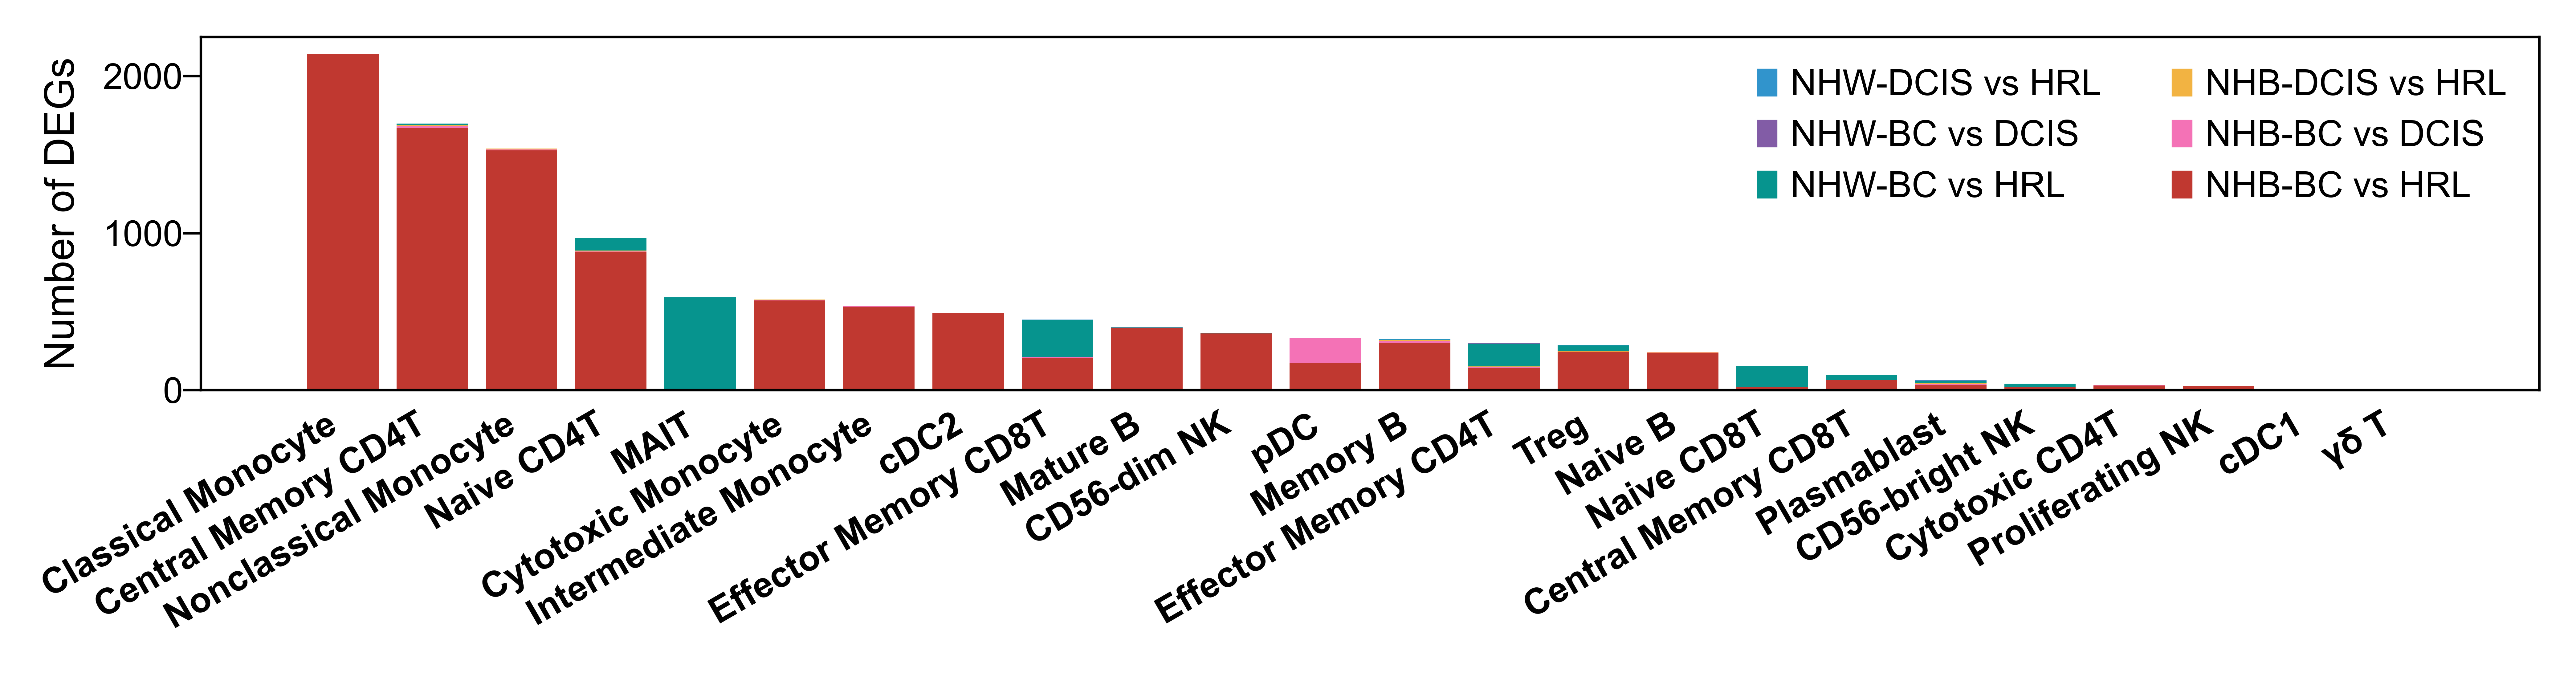

In [28]:
import matplotlib.pyplot as plt
import pandas as pd

# define order explicitly
hue_order = [
    'NHW-DCIS vs HRL',
    'NHW-BC vs DCIS',
    'NHW-BC vs HRL',
    
    'NHB-DCIS vs HRL',
    'NHB-BC vs DCIS',
    'NHB-BC vs HRL'
]

# pivot to wide format
tbl_wide = (
    tbl_long
    .pivot_table(
        index='celltype',
        columns='group',
        values='count',
        aggfunc='sum'
    )
    .reindex(index=celltype_order, columns=hue_order)
    .fillna(0)
)

# plotting
fig, ax = plt.subplots(figsize=(7, 1.8))

bottom = pd.Series(0, index=tbl_wide.index)

for grp in reversed(hue_order):
    ax.bar(
        tbl_wide.index,
        tbl_wide[grp],
        bottom=bottom,
        color=group_palette[grp],
        label=grp
    )
    bottom += tbl_wide[grp]

# 🔑 FIX: set y-limits using stacked total
ax.set_ylim(0, bottom.max() * 1.05)

# formatting
ax.set_xlabel('')
ax.set_ylabel('Number of DEGs', fontsize=8)
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=30,
    ha='right',
    fontsize=7,
    fontweight='bold'
)
ax.tick_params(axis='y', labelsize=7)


# legend (top-to-bottom order preserved)
handles = [
    plt.Rectangle((0, 0), 1, 1, color=group_palette[g])
    for g in hue_order
]
ax.legend(
    handles,
    hue_order,
    title='',
    bbox_to_anchor=(1, 1),
    loc='upper right',
    frameon=False,
    fontsize=7,
    ncol=2
)

plt.tight_layout()
plt.savefig('plots/F3/RRE_numDEG_bysstage_total.svg')